<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Vector Tile Reader](https://github.com/Query-farm/vgi-mvt-typescript)

Decode PMTiles and XYZ vector tiles into DuckDB rows with GEOMETRY columns, natively or in the browser.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-mvt-typescript/blob/main/notebooks/02_valid_geometry_wrong_tile_address.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-mvt-typescript/blob/main/notebooks/README.md)

## Valid geometry can still be in the wrong place

**Does a successful decode prove that a tile was placed correctly?** A vector tile carries coordinates local to its grid. The supplied XYZ address places those coordinates geographically. Decode the same known fixture under its recorded address and a deliberately incorrect address, then compare identity, validity and position.

The unchanged GDAL test tile comes from **`test/fixtures/xyz/2/2/1.mvt`**, so its reference address is **z=2, x=2, y=1**. It contains four city records with fixture/historical attributes and two invented polygons. It is not a current place dataset. The baseline is already quantized tile geometry; no ground-truth survey or original precision is claimed.


### Assign an address deliberately

`ASSIGNED_X = 1` is the **known wrong-address control**. Zoom remains 2 and Y remains 1. Change only X to **2** for the experiment, which restores the fixture's recorded address. Both X values are within the legal tile-index range at zoom 2: syntactically valid arguments do not establish correct provenance.

Only the supplied address changes. Source bytes, decoding options, names and attributes stay fixed. There is no write or network data retrieval.


In [1]:
ASSIGNED_X = 1  # Known wrong-address control. Experiment: 2 (recorded address).


In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.32":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.32"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")


In [3]:
from IPython.display import display
from vgi_notebooks import check_runtime, connect, theme, prose, prepare

check_runtime()
prepare("mvt-typescript")
import mvt_typescript_example as example

example.validate_x(ASSIGNED_X)
example.verify_fixtures()
session = connect(globals())
theme()


### Attach the released native reader

The literal v0.1.0 launcher resolves a checksum-verified release for the host platform. Spatial supplies SQL measurements and coordinate transforms; it does not infer a tile address from the fixture's city labels. Setup uses an isolated empty SQL-secret directory.


In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
INSTALL spatial;
LOAD spatial;
ATTACH 'mvt' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-mvt-typescript@v0.1.0');


,Success


### Read identical bytes with two addresses

Read each version once, requesting **EPSG:3857 Web Mercator** coordinates. Preserve every feature and property object. The raw tile has no encoded IDs; for this controlled fixture, layer plus the complete property object uniquely identifies a row. This is a comparison key for these bytes, not a universal identity rule.

XYZ counts Y from the north. An MBTiles TMS row would need conversion before use; this fixture already has XYZ provenance.


In [5]:
%%sql
CREATE TABLE reference AS
SELECT * FROM mvt.main.read_mvt('fixtures/2-2-1.mvt',2,2,1,coordinates:='web_mercator');
CREATE TABLE selected AS
SELECT * FROM mvt.main.read_mvt('fixtures/2-2-1.mvt',2,{{ ASSIGNED_X }},1,coordinates:='web_mercator');
CREATE TABLE pairs AS
SELECT r.layer,r.properties,coalesce(r.properties->>'name',r.properties->>'code') AS fixture_label,
       r.geometry AS reference_geometry,s.geometry AS selected_geometry,
       ST_Equals(r.geometry,s.geometry) AS geometry_equal
FROM reference r JOIN selected s ON r.layer=s.layer AND r.properties=s.properties;


,Count


In [6]:
%%sql population <<
SELECT (SELECT count(*) FROM reference) AS reference_rows,
       (SELECT count(*) FROM selected) AS selected_rows,
       (SELECT count(*) FROM pairs) AS matched_properties,
       (SELECT count(*) FROM selected WHERE ST_IsValid(geometry) AND NOT ST_IsEmpty(geometry)) AS valid_geometries,
       (SELECT sha256(content) FROM read_blob('fixtures/2-2-1.mvt')) AS input_sha256;


In [7]:
display(population)
r=population.iloc[0]
assert r.reference_rows==r.selected_rows==r.matched_properties==r.valid_geometries==6
prose(f"Both reads return **{int(r.reference_rows)} rows**, all **{int(r.matched_properties)} property objects match**, "
      f"and all **{int(r.valid_geometries)} selected geometries are valid and nonempty**. "
      "These checks alone cannot establish that the tile was assigned its recorded address.")


,reference_rows,selected_rows,matched_properties,valid_geometries,input_sha256
0,6,6,6,6,f0617c1490d9f9ceb86caded066793840bf7f987c35d0d...


Both reads return **6 rows**, all **6 property objects match**, and all **6 selected geometries are valid and nonempty**. These checks alone cannot establish that the tile was assigned its recorded address.

### Test the displacement implied by the address

At zoom 2, adjacent tile columns span a quarter of the Web Mercator world width: **40,075,016.685578488 / 4 metres**. For the four point features, compare the returned eastings and northings with the expected shift `(ASSIGNED_X − 2)` times that width. A wrong X changes longitude by **90° per tile column** at this zoom.

SQL also transforms the points to longitude/latitude for a schematic plot with fixed axes and no basemap. The signed easting difference remains a separate **projected** quantity, not a ground-distance estimate.


In [8]:
%%sql point_shifts <<
CREATE TABLE point_shifts AS
SELECT fixture_label,
       ST_X(ST_Transform(reference_geometry,'EPSG:3857','EPSG:4326',always_xy:=true)) AS reference_lon,
       ST_Y(ST_Transform(reference_geometry,'EPSG:3857','EPSG:4326',always_xy:=true)) AS reference_lat,
       ST_X(ST_Transform(selected_geometry,'EPSG:3857','EPSG:4326',always_xy:=true)) AS selected_lon,
       ST_Y(ST_Transform(selected_geometry,'EPSG:3857','EPSG:4326',always_xy:=true)) AS selected_lat,
       ST_X(selected_geometry)-ST_X(reference_geometry) AS easting_change_m,
       ST_Y(selected_geometry)-ST_Y(reference_geometry) AS northing_change_m,
       ({{ ASSIGNED_X }}-2)*40075016.685578488/4 AS expected_easting_change_m
FROM pairs WHERE layer='cities';
SELECT * FROM point_shifts ORDER BY fixture_label;


In [9]:
display(point_shifts)
max_error=(point_shifts.easting_change_m-point_shifts.expected_easting_change_m).abs().max()
prose(f"With assigned X **{ASSIGNED_X}**, all four points shift **{point_shifts.easting_change_m.iloc[0]/1000:+,.3f} projected km** eastward "
      f"(**{point_shifts.selected_lon.iloc[0]-point_shifts.reference_lon.iloc[0]:+.0f}° longitude**). "
      f"The maximum difference from the tile-width calculation is **{max_error:.3g} metres**. "
      + ("The recorded address is restored; the position difference is zero." if ASSIGNED_X==2 else
         "The known wrong address leaves validity and attributes intact while moving the points far from their reference positions."))


,fixture_label,reference_lon,reference_lat,selected_lon,selected_lat,easting_change_m,northing_change_m,expected_easting_change_m
0,Berlin,13.403320,52.522906,-76.596680,52.522906,-1.001875e+07,0.0,-1.001875e+07
1,Milan,9.184570,45.460131,-80.815430,45.460131,-1.001875e+07,0.0,-1.001875e+07
2,Paris,2.351074,48.850258,-87.648926,48.850258,-1.001875e+07,0.0,-1.001875e+07
3,Vienna,16.369629,48.210032,-73.630371,48.210032,-1.001875e+07,0.0,-1.001875e+07


With assigned X **1**, all four points shift **-10,018.754 projected km** eastward (**-90° longitude**). The maximum difference from the tile-width calculation is **1.86e-09 metres**. The known wrong address leaves validity and attributes intact while moving the points far from their reference positions.

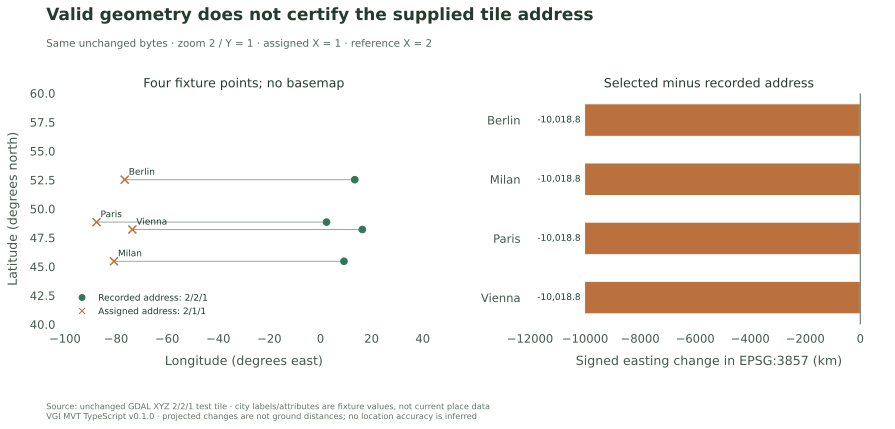

In [10]:
example.address_changes(point_shifts, ASSIGNED_X)


### Keep provenance separate from geometry validity

Require exactly six unique fixture keys, no missing or extra properties, valid geometries, the requested tile address and unchanged source bytes. Check all four point displacements against the independent width calculation. Compare geometric equality as a separate outcome: it holds only when the assigned address matches this fixture's recorded address.

These are fixture consistency checks. They do not authenticate an arbitrary file's origin or infer a correct address from its content.


In [11]:
%%sql checks <<
SELECT 'six reference and selected features' AS check_name,
 (SELECT count(*)=6 FROM reference) AND (SELECT count(*)=6 FROM selected) AS passed
UNION ALL SELECT 'unique fixture layer-property keys',
 (SELECT count(DISTINCT(layer,properties::VARCHAR))=6 FROM reference) AND
 (SELECT count(DISTINCT(layer,properties::VARCHAR))=6 FROM selected)
UNION ALL SELECT 'no properties missing or added',NOT EXISTS(
 (SELECT layer,properties FROM reference EXCEPT ALL SELECT layer,properties FROM selected)
 UNION ALL (SELECT layer,properties FROM selected EXCEPT ALL SELECT layer,properties FROM reference))
UNION ALL SELECT 'six matched property objects',(SELECT count(*)=6 FROM pairs)
UNION ALL SELECT 'input has no encoded feature IDs',(SELECT count(feature_id)=0 FROM reference)
UNION ALL SELECT 'selected geometries valid and nonempty',(SELECT bool_and(ST_IsValid(geometry) AND NOT ST_IsEmpty(geometry)) FROM selected)
UNION ALL SELECT 'assigned XYZ address is returned',(SELECT bool_and(z=2 AND x={{ ASSIGNED_X }} AND y=1) FROM selected)
UNION ALL SELECT 'four point rows and two polygon rows',(SELECT count(*)=4 FROM point_shifts) AND (SELECT count(*)=2 FROM pairs WHERE layer='regions')
UNION ALL SELECT 'point easting change matches tile width',(SELECT bool_and(abs(easting_change_m-expected_easting_change_m)<1e-6) FROM point_shifts)
UNION ALL SELECT 'point northing is unchanged',(SELECT bool_and(abs(northing_change_m)<1e-6) FROM point_shifts)
UNION ALL SELECT 'longitude change matches one-quarter world',(SELECT bool_and(abs((selected_lon-reference_lon)-({{ ASSIGNED_X }}-2)*90)<1e-9) FROM point_shifts)
UNION ALL SELECT 'geometry equality follows recorded address',(SELECT bool_and(geometry_equal=({{ ASSIGNED_X }}=2)) FROM pairs);


In [12]:
display(checks)
assert len(checks)==12 and checks.passed.notna().all() and checks.passed.all()
prose(f"All **{len(checks)} checks** pass, including the known address-dependent outcome. "
      "A successful decode and valid geometry are necessary checks; the supplied XYZ provenance remains essential.")


,check_name,passed
0,six reference and selected features,True
1,unique fixture layer-property keys,True
2,no properties missing or added,True
3,six matched property objects,True
4,input has no encoded feature IDs,True
5,selected geometries valid and nonempty,True
6,assigned XYZ address is returned,True
7,four point rows and two polygon rows,True
8,point easting change matches tile width,True
9,point northing is unchanged,True


All **12 checks** pass, including the known address-dependent outcome. A successful decode and valid geometry are necessary checks; the supplied XYZ provenance remains essential.

### Restore the recorded tile column

Change only `ASSIGNED_X` from **1 to 2**, restart and Run All. Predict unchanged source hash, six matched property objects, valid-geometry count and row population. The position difference should become zero, with selected and reference markers coinciding. Fixed axes make the two runs directly comparable.

The city labels remain fixture values in both runs, not evidence that the assigned location is correct. This control demonstrates why a consumer must preserve tile-address provenance. Restore **1** for the saved wrong-address default.


In [13]:
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
session.close()


<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-mvt-typescript](https://github.com/Query-farm/vgi-mvt-typescript)
